# Designing a Topic Forest for Findable and Stable Learning History
**HCI 2026 – Group 19 – Milestone 3 (simplified model, working version)**

In our prototype the student asks the AI one prompt after another, and after **every** prompt the knowledge tree is updated. At each step the system decides where the new prompt goes:

- **(a)** add it to an existing topic,
- **(b)** open a new subtopic under an existing topic (new branch),
- **(c)** open a new topic directly under the subject (new tree),
- **(e)** open a new topic *and* move related older prompts into it (reorganize).

This decision trades off **semantic fit**, a **tidy structure** (topics neither overloaded nor near-empty) and **stability** (moving old prompts breaks the user's mental map). We formulate **one step** as an integer program, solve it with Gurobi, apply the result to the tree and continue with the next prompt. Running this over a scripted study session gives the sequence of trees the user would see.

**How to use this notebook.** All numbers that we may want to change live in a few places: the questions (`session.py`), the LLM answer (`judge_scores.json`, Section 2) and the weights (Section 3). Edit them and re-run all cells.

*Scope of this version:* one subject ("deep learning"), candidate new topics come with a parent fixed by the judge, at most one new topic per step, old topics are never deleted.

**Setup.** In Google Colab the next cell downloads the repository (the notebook needs `session.py`, `judge_prompt.py`, `visualization.py` and `judge_scores.json` from it) and installs Gurobi; Gurobi's free size-limited license that comes with `pip install gurobipy` is enough for this model (about 60 variables per step). Run locally, the cell does nothing.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/UxAzhangxiaohua/hci_m3/blob/main/ui_optimization.ipynb)

In [1]:
import os, sys, subprocess

REPO = "https://github.com/UxAzhangxiaohua/hci_m3.git"
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not os.path.exists("hci_m3"):
        subprocess.run(["git", "clone", "-q", REPO], check=True)
    os.chdir("hci_m3")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gurobipy"], check=True)
print("running in", "Colab" if IN_COLAB else "a local Jupyter", "| working directory:", os.getcwd())

running in a local Jupyter | working directory: /home/claude/out


In [2]:
# !pip install -r requirements.txt   # gurobipy, numpy, matplotlib, pandas, pillow
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from gurobipy import Model, GRB, quicksum

pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 60)

# 1. The scripted study session
***
**Start.** The student has already asked two prompts, so the tree starts like the one in our prototype:

```
deep learning                      (the subject = root of the tree)
├── Deep learning basics   ● p0    "Explain what deep learning is"
└── Gradient descent       ● p1    "What is gradient descent?"
```

**Then eight new questions arrive one by one** (`n1` … `n8`). Which **new topics** could be created along the way is not written by us: an LLM **proposes** them (Section 2), each with the parent it would hang under. A proposed topic does **not** exist yet: at every step the solver decides whether to create it. A proposal that is not created stays **open** and can still be created at a later step, e.g. when a second related question arrives.

`w` is the cost weight of moving a prompt later on. **We set `w = 1` for every prompt** (all moves cost the same). This is an assumption: in the app it could be derived from how often a prompt was reopened recently.

The session is defined in **`session.py`** (next to this notebook). The LLM prompt (Section 2) is built from the same file by `judge_prompt.py`, so the LLM sees exactly the questions that are optimized here. To change the session, edit `session.py`, regenerate the prompt with `python judge_prompt.py > judge_prompt.txt`, get a new answer, then re-run this notebook.

*The questions are a scripted example. Replace them with the real session used in Milestone 4.*

In [3]:
from session import SUBJECT, INITIAL_TOPICS, INITIAL_PROMPTS, SESSION, AUTHOR_PROPOSALS, AUTHOR_SCORES, all_prompts, topic_path

pd.DataFrame({"question": [s["text"] for s in SESSION]},
             index=pd.Index([f'{k + 1}: {s["id"]}' for k, s in enumerate(SESSION)], name="step"))

,question
step,
1: n1,What does the learning rate do?
2: n2,How does backpropagation compute the gradients?
3: n3,Chain rule through a 2-layer network
4: n4,SGD vs. mini-batch gradient descent
5: n5,How does Adam adapt the learning rate?
6: n6,Why do gradients vanish in deep networks?
7: n7,Does the gradient shrink layer by layer with sigmoid?
8: n8,What is momentum in SGD?


# 2. Proposals and semantic fit $s_{pc}$ from the LLM
***
The solver cannot judge meaning. **Every time a new question arrives**, one LLM prompt does the two language tasks **in this order**:

1. **Propose.** Decide whether the tree needs a new topic for the new question: only if the question would fit it perfectly (5) and every topic existing at that point at most 4. Name it (1–3 words) and choose its parent (an existing topic, an open proposal, or directly under the subject). At most one proposal per question.
2. **Judge.** Rate the new question against every topic of the current tree, every open proposal and the new proposal; and rate each earlier question against the topics it has not been rated against yet (in practice: the new proposal). Rubric:

| score | meaning |
|---|---|
| 5 | the question is squarely about this topic |
| 4 | it belongs to a more specific subtopic of this topic that is not in the list |
| 3 | same broader area, different topic |
| 2 | loosely related |
| 1 | unrelated |

The ratings of **old questions against new proposals** matter: they decide whether moving an old question into a new topic improves the fit.

**A fixed template, filled in at every step.** The module **`judge_prompt.py`** builds the prompt from fixed parts (context, propose rules, rubric, judge rules, output format) and inserts what changes at each step: the current tree with the questions in each topic, the open proposals, the scores still missing, and the new question (`judge_prompt.step_prompt`). This is exactly what the prototype sends through the LLM API after every question.

**Only the past is visible.** At step $k$ the LLM sees the tree *after* step $k-1$ and the $k$-th question, nothing later. A score is asked once, when both the question and the topic exist, and is never re-asked later; so a later branch cannot change the score of an earlier question (Section 5 shows at which step every score was asked).

**How the answers are collected** (Section 5): with an API key the notebook calls the model itself; without one it writes the prompt of the next step to `llm_steps/`, you paste it into the chat and save the answer, and the notebook continues. Prompts and answers stay in `llm_steps/` as the record for the report. Until all steps are answered, the notebook uses a fallback: `judge_scores.json` (an earlier run that sent the whole session at once) or, if that is missing, the authors' proposals and scores in `session.py`.

We rescale the score to  
$s_{pc} = (j_{pc}-1)/4 \in \{0, 0.25, 0.5, 0.75, 1\}$.  
 In the full system it could be mixed with an embedding similarity,   
 $s = \omega\,\tfrac{j-1}{4} + (1-\omega)\tfrac{1+\cos}{2}$;   
 here we use the judge only ($\omega = 1$).

In [4]:
import os, json
import judge_prompt

PLACED_0 = {p: d["topic"] for p, d in INITIAL_PROMPTS.items()}     # questions already in the tree

def set_llm_data(proposals, scores):
    # make proposals {question: {"id","label","parent"}} and scores {question: {topic: 1..5}} the current inputs
    global PROPOSALS, JUDGE, ALL_TOPICS, ALL_LABELS
    PROPOSALS, JUDGE = proposals, scores
    ALL_TOPICS = {**INITIAL_TOPICS, **{t["id"]: dict(label=t["label"], parent=t["parent"]) for t in proposals.values()}}
    ALL_LABELS = {c: t["label"] for c, t in ALL_TOPICS.items()}

def s(p, c):
    return (int(JUDGE[p].get(c, 1)) - 1) / 4

# fallback inputs, used until all steps have been answered (Section 5)
BATCH_FILE = "judge_scores.json"
if os.path.exists(BATCH_FILE) and "proposals" in json.load(open(BATCH_FILE)):
    set_llm_data(*judge_prompt.parse_batch(open(BATCH_FILE).read(), SUBJECT, INITIAL_TOPICS, all_prompts(), PLACED_0))
    FALLBACK_SOURCE = "earlier LLM run with the whole session at once (judge_scores.json)"
else:
    set_llm_data(AUTHOR_PROPOSALS, AUTHOR_SCORES)
    FALLBACK_SOURCE = "proposals and scores written by the authors (session.py)"
SCORE_SOURCE = "fallback: " + FALLBACK_SOURCE
print("Fallback inputs loaded:", FALLBACK_SOURCE)

Fallback inputs loaded: earlier LLM run with the whole session at once (judge_scores.json)


# 3. Design parameters and weights
***
All weights are on the scale of $s_{pc}\in[0,1]$, i.e. "how much fit is this worth"; one judge level is worth 0.25.

| Symbol | Value | Meaning and justification |
|---|---|---|
| $U$ | 3 | Preferred maximum prompts per topic. Small on purpose so that overload happens within a short session; for real use ≈ 5–7 (our app splits branches above 7 leaves). |
| $L$ | 2 | Preferred minimum prompts per topic. A topic with one prompt adds a row but no grouping. Applies to every topic, also to an existing topic that a move would leave (almost) empty. |
| $\lambda$ | 0.20 | Cost of opening a new topic: it must improve fit by more than about one judge level, together with $\beta$ for a one-prompt topic. |
| $\beta$ | 0.12 | Cost per prompt above $U$ or below $L$. About half a judge level, so balance never outweighs a clear semantic difference; chosen off the 0.05 grid of the other weights so that two options never cost exactly the same (no ties between decisions). |
| $\mu$ | 0.10 | Cost per moved old prompt (times its weight $w_p$). |
| $F$ | 0.15 | Fixed cost if *anything* old moves: the first change to a familiar structure is the most noticeable one. |
| `MAX_NEW` | 1 | At most one new topic per step, so the tree grows slowly. |

In [5]:
PARAMS = dict(
    U=3,          # preferred max prompts per topic
    L=2,          # preferred min prompts per topic
    lam=0.20,     # cost of opening a new topic
    beta=0.12,    # cost per prompt of overflow / underflow
    mu=0.10,      # cost per moved prompt (times w_p)
    F=0.15,       # fixed cost of any reorganization
    MAX_NEW=1,    # max number of new topics per step
)

# 4. The integer program for one step
***
At a step, the tree before the step is fixed input:

- $C^{old}$: topics that exist; $C^{new}$: **open proposals**, i.e. topics the LLM proposed for this question or an earlier one, not created yet, whose parent exists; $C = C^{old}\cup C^{new}$
- $P^{old}$: prompts already in the tree, each in topic $c^0(p)$; $n$: the new prompt; $P = P^{old}\cup\{n\}$

### Decision variables
| Variable | Meaning |
|---|---|
| $q_{pc}\in\{0,1\}$ | prompt $p$ is placed in topic $c$ after this step |
| $y_c\in\{0,1\}$, $c\in C^{new}$ | candidate $c$ is created |
| $m_p\in\{0,1\}$, $p\in P^{old}$ | old prompt $p$ is moved away from $c^0(p)$ |
| $z\in\{0,1\}$ | a reorganization happens in this step |
| $o_c, u_c\ge 0$ | slack: topic $c$ over $U$ / under $L$ |

### Constraints
$$
\begin{aligned}
&\textstyle\sum_{c\in C} q_{pc} = 1 && \forall p\in P && \text{(1) each prompt in exactly one topic}\\
&q_{pc} \le y_c && \forall p\in P,\ c\in C^{new} && \text{(2) only into topics that exist}\\
&\textstyle y_c \le \sum_{p} q_{pc} && \forall c\in C^{new} && \text{(3) no empty new topic}\\
&\textstyle \sum_{p} q_{pc} \le U + o_c && \forall c\in C && \text{(4) too full (soft)}\\
&\textstyle \sum_{p} q_{pc} \ge L\,y_c - u_c && \forall c\in C && \text{(5) too sparse (soft), with } y_c = 1 \text{ for } c\in C^{old}\\
&m_p = 1 - q_{p,c^0(p)} && \forall p\in P^{old} && \text{(6) track moves}\\
&m_p \le z && \forall p\in P^{old} && \text{(7) any move is a reorganization}\\
&\textstyle\sum_{c\in C^{new}} y_c \le \texttt{MAX\_NEW} && && \text{(8) slow growth}
\end{aligned}
$$

### Objective
$$
\max\;
\underbrace{\sum_{p,c} s_{pc}\,q_{pc}}_{\text{semantic fit}}
-\underbrace{\lambda\sum_{c\in C^{new}} y_c}_{\text{new topics}}
-\underbrace{\beta\sum_{c\in C} (o_c+u_c)}_{\text{imbalance}}
-\underbrace{\mu\sum_{p\in P^{old}} w_p\,m_p - F\,z}_{\text{disruption}}
$$

Without (4), (5) and the disruption terms, the optimum would be "put every prompt in its best topic", which a simple rule can find. These terms create the trade-off.

**State.** A *state* is the tree at a moment: which topics exist (`topics`), where every prompt is (`assign`) and the move weights (`w`). `solve_step` takes the state and the next prompt and returns where every prompt goes after the step.

In [6]:
def initial_state():
    return dict(topics={c: dict(t) for c, t in INITIAL_TOPICS.items()},
                assign={p: d["topic"] for p, d in INITIAL_PROMPTS.items()},
                w={p: d["w"] for p, d in INITIAL_PROMPTS.items()})

STEP_K = {st["id"]: k for k, st in enumerate(SESSION, start=1)}

def candidates_of(state, step):
    # open proposals: proposed for this question or an earlier one, not created yet, parent exists
    k = STEP_K[step["id"]]
    return {t["id"]: dict(label=t["label"], parent=t["parent"]) for q, t in PROPOSALS.items()
            if STEP_K[q] <= k and t["id"] not in state["topics"]
            and (t["parent"] == SUBJECT or t["parent"] in state["topics"])}

def solve_step(state, step, params=PARAMS, verbose=False):
    U, L = params["U"], params["L"]
    n = step["id"]
    C_old = list(state["topics"])
    C_new = list(candidates_of(state, step))
    C = C_old + C_new
    P_old = list(state["assign"])
    P = P_old + [n]
    c0 = state["assign"]

    # ==== 1. Create the (empty) model ====
    model = Model(f"step_{n}")
    model.Params.OutputFlag = 1 if verbose else 0

    # ==== 2. Add decision variables ====
    q = {(p, c): model.addVar(vtype=GRB.BINARY, name=f"q[{p},{c}]") for p in P for c in C}
    y = {c: model.addVar(vtype=GRB.BINARY, name=f"y[{c}]") for c in C_new}
    m = {p: model.addVar(vtype=GRB.BINARY, name=f"m[{p}]") for p in P_old}
    z = model.addVar(vtype=GRB.BINARY, name="z")
    o = {c: model.addVar(lb=0, name=f"o[{c}]") for c in C}
    u = {c: model.addVar(lb=0, name=f"u[{c}]") for c in C}

    # ==== 3. Add constraints ====
    for p in P:                                                                   # (1)
        model.addConstr(quicksum(q[p, c] for c in C) == 1, name=f"one_topic[{p}]")
    for c in C_new:
        for p in P:                                                               # (2)
            model.addConstr(q[p, c] <= y[c], name=f"exists[{p},{c}]")
        model.addConstr(y[c] <= quicksum(q[p, c] for p in P), name=f"not_empty[{c}]")        # (3)
    for c in C:
        model.addConstr(quicksum(q[p, c] for p in P) <= U + o[c], name=f"full[{c}]")        # (4)
        exists = y[c] if c in y else 1
        model.addConstr(quicksum(q[p, c] for p in P) >= L * exists - u[c], name=f"sparse[{c}]")  # (5)
    for p in P_old:
        model.addConstr(m[p] == 1 - q[p, c0[p]], name=f"moved[{p}]")              # (6)
        model.addConstr(m[p] <= z, name=f"reorg[{p}]")                            # (7)
    model.addConstr(quicksum(y.values()) <= params["MAX_NEW"], name="max_new")   # (8)

    # ==== 4. Specify objective function ====
    fit = quicksum(s(p, c) * q[p, c] for p in P for c in C)
    growth = params["lam"] * quicksum(y.values())
    imbalance = params["beta"] * (quicksum(o.values()) + quicksum(u.values()))
    disruption = params["mu"] * quicksum(state["w"][p] * m[p] for p in P_old) + params["F"] * z
    model.setObjective(fit - growth - imbalance - disruption, GRB.MAXIMIZE)

    # ==== 5. Optimize model ====
    model.optimize()
    assert model.Status == GRB.OPTIMAL, f"Gurobi status {model.Status}"

    # ==== 6. Extract solution: where every prompt is after this step ====
    new_assign = {p: next(c for c in C if q[p, c].X > 0.5) for p in P}
    return new_assign, model.ObjVal

`evaluate_step` scores **any** decision for a step with the same objective, so that we can compare the optimum with human-made rules. On the solver's decision it must return the solver's objective value (a check of the implementation). `action` translates a decision into (a)/(b)/(c)/(e).

In [7]:
def evaluate_step(state, step, new_assign, params=PARAMS):
    U, L = params["U"], params["L"]
    n, cands = step["id"], candidates_of(state, step)
    P = list(state["assign"]) + [n]
    topics = list(state["topics"]) + list(cands)
    size = {c: sum(new_assign[p] == c for p in P) for c in topics}
    created = [c for c in cands if size[c] > 0]
    moved = [p for p in state["assign"] if new_assign[p] != state["assign"][p]]
    over = sum(max(0, size[c] - U) for c in topics)
    under = sum(max(0, L - size[c]) for c in list(state["topics"]) + created)
    parts = {
        "fit": sum(s(p, new_assign[p]) for p in P),
        "new topics": -params["lam"] * len(created),
        "imbalance": -params["beta"] * (over + under),
        "disruption": -(params["mu"] * sum(state["w"][p] for p in moved) + params["F"] * (len(moved) > 0)),
    }
    parts["objective"] = sum(parts.values())
    return parts

def action(state, step, new_assign):
    c = new_assign[step["id"]]
    moved = [p for p in state["assign"] if new_assign[p] != state["assign"][p]]
    if c in state["topics"]:
        base = "(a) add to existing topic"
    elif ALL_TOPICS[c]["parent"] == SUBJECT:
        base = "(c) new tree"
    else:
        base = "(b) new branch"
    return f"(e) reorganize: move {', '.join(moved)} + {base[4:]}" if moved else base

def code_of(act):        # short letter for tables: a, b, c, or e
    return act[1]

# 5. Run the session step by step
***
`run_session` starts from the initial tree, and for each new prompt: asks the decision rule (here the IP) where everything goes, records the action, applies it to the tree (creates the chosen topic, moves prompts) and continues with the next prompt. First (5a) the LLM's proposals and scores are collected step by step along this loop; then (5b) the session is run with them.

The table in 5b shows the solver's decision in every step: where the new question was placed and how well it fits there (judge score 1–5 and the fit $s$), which topic was created and which earlier questions were moved. *Why* the solver decided this way, compared with the alternatives, is shown in Section 6 ("Why each decision?").

In [8]:
def apply(state, step, new_assign):
    topics = dict(state["topics"])
    for c, t in candidates_of(state, step).items():
        if c in new_assign.values():
            topics[c] = dict(t)
    return dict(topics=topics, assign=dict(new_assign), w={**state["w"], step["id"]: step["w"]})

def ip_policy(state, step, params):
    return solve_step(state, step, params)[0]

def run_session(policy=ip_policy, params=PARAMS):
    state, history = initial_state(), []
    for k, step in enumerate(SESSION, start=1):
        new_assign = policy(state, step, params)
        history.append(dict(k=k, step=step, before=state, after=apply(state, step, new_assign),
                            action=action(state, step, new_assign),
                            parts=evaluate_step(state, step, new_assign, params), params=params))
        state = history[-1]["after"]
    return history

## 5a. Ask the LLM step by step
***
`collect_steps` walks through the session like the prototype: at step $k$ it builds the step prompt from the **current** tree (after step $k-1$) and the $k$-th question, gets the LLM's answer, adds the proposal and scores, lets the IP decide the step and continues. Every score is stored with the step at which it was asked.

- **With an API key** (`ANTHROPIC_API_KEY` set in the environment, in Colab via *Secrets*) the notebook calls `LLM_MODEL` itself.
- **Without a key** it stops at the first step that has no answer yet and prints what to do: paste `llm_steps/<id>_prompt.txt` into the chat, save the reply as `llm_steps/<id>_answer.json` and re-run this cell. It then continues to the next step (8 times in total).
- If an answer was given for a different tree (e.g. after changing the weights), the notebook says so; delete that answer and the later ones and collect them again.
- **Replay** (`REPLAY_FROM_BATCH = True`): a step without an answer and without a key is answered from the earlier batch run in `judge_scores.json` (same proposal, same scores), and the notebook says so. This runs the whole step-by-step pipeline, but the scores still come from one call that saw the whole session, so it does **not** remove the influence of later questions; for the report only real step answers do.

In [9]:
STEP_DIR = "llm_steps"
LLM_MODEL = "claude-sonnet-5-5"          # used with an API key
STEP_SOURCE = "Claude Sonnet 5.5, one step prompt per question"   # <- declare the model / interface you used
REPLAY_FROM_BATCH = False                # True only for the ablation "batch vs. step": the batch saw every later question,
                                         # so its proposals and scores leak the future into earlier steps
USE_CLI = True                           # no API key: use the Claude Code CLI on a Claude subscription, if installed

def replay_answer(n, placed, missing):
    # Build the answer of step n from the batch run in judge_scores.json: same proposal, same scores.
    # This demonstrates the step-by-step pipeline; the scores themselves still come from the batch run.
    props, scores = judge_prompt.parse_batch(open(BATCH_FILE).read(), SUBJECT, INITIAL_TOPICS, all_prompts(), PLACED_0)
    p = props.get(n)
    new_id = p["id"] if p else None
    ren = lambda c: "NEW" if c == new_id else c
    topics_now = [c for c in ALL_TOPICS_NOW]
    answer = {
        "proposal": None if not p else {"id": "NEW", "name": p["label"],
                                        "parent": "ROOT" if p["parent"] == SUBJECT else p["parent"]},
        "new_question": {ren(c): scores[n][c] for c in topics_now + ([new_id] if p else [])},
        "earlier_questions": {q: {ren(c): scores[q][c] for c in missing.get(q, []) + ([new_id] if p else [])}
                              for q in placed},
    }
    return json.dumps(answer)

def ask_api(prompt):
    key = os.environ.get("ANTHROPIC_API_KEY")
    if not key:
        return None
    import urllib.request
    req = urllib.request.Request(
        "https://api.anthropic.com/v1/messages", method="POST",
        data=json.dumps({"model": LLM_MODEL, "max_tokens": 2000, "temperature": 0,
                         "messages": [{"role": "user", "content": prompt}]}).encode(),
        headers={"x-api-key": key, "anthropic-version": "2023-06-01", "content-type": "application/json"})
    with urllib.request.urlopen(req, timeout=120) as r:
        return "".join(b.get("text", "") for b in json.loads(r.read())["content"])

def ask_cli(prompt):
    # One fresh `claude -p` call per step: own process, empty folder, no tools, no session kept, so the model
    # sees only this step's prompt (the tree so far and the new question), never a later question.
    # Runs on the logged-in Claude subscription; an API key in the environment is removed so it is never billed.
    import glob, shutil, subprocess, tempfile
    if not USE_CLI:
        return None
    bundled = sorted(glob.glob(os.path.expanduser(
        "~/.vscode/extensions/anthropic.claude-code-*/resources/native-binary/claude")))
    exe = shutil.which("claude") or (bundled[-1] if bundled else None)
    if exe is None:
        return None
    env = {k: v for k, v in os.environ.items()
           if k not in ("ANTHROPIC_API_KEY", "ANTHROPIC_AUTH_TOKEN", "CLAUDECODE", "CLAUDE_PID")
           and not k.startswith(("CLAUDE_CODE_", "CLAUDE_AGENT_SDK"))}
    cmd = [exe, "-p", "--model", LLM_MODEL, "--safe-mode", "--tools", "", "--no-session-persistence",
           "--system-prompt", "You rate how well study questions fit topics. Answer with one JSON object only.",
           "--output-format", "json"]
    with tempfile.TemporaryDirectory() as empty:
        r = subprocess.run(cmd, input=prompt, capture_output=True, text=True, cwd=empty, env=env, timeout=600)
    data = json.loads(r.stdout)
    if data.get("is_error"):
        print(f"   claude CLI could not answer ({data.get('result') or data.get('subtype')}); "
              "log in with `claude` once, or answer the step by hand")
        return None
    print("   answered by", next(iter(data.get("modelUsage") or {}), LLM_MODEL))
    return data["result"]

def collect_steps(params=PARAMS):
    # -> (proposals, scores, asked_at) when every step is answered, otherwise None
    os.makedirs(STEP_DIR, exist_ok=True)
    REPLAYED.clear()
    state = initial_state()
    proposals, scores, asked = {}, {p: {} for p in all_prompts()}, {p: {} for p in all_prompts()}
    for k, step in enumerate(SESSION, start=1):
        n = step["id"]
        set_llm_data(proposals, scores)                        # only what is known before step k
        open_now = candidates_of(state, step)
        topics_now = {**state["topics"], **open_now}
        placed = state["assign"]
        missing = {q: [c for c in topics_now if c not in scores[q]] for q in placed}
        prompt = judge_prompt.step_prompt(SUBJECT, topics_now, placed, all_prompts(), step["text"],
                                          open_ids=open_now, missing=missing)
        pf, af = f"{STEP_DIR}/{n}_prompt.txt", f"{STEP_DIR}/{n}_answer.json"
        if os.path.exists(af) and os.path.exists(pf) and open(pf).read() != prompt:
            print(f"Step {k}: {af} answers a different tree than the current one (weights or an earlier answer "
                  f"changed). Delete {af} and the answers of the later steps, then re-run this cell.")
            return None
        with open(pf, "w") as f:
            f.write(prompt)
        replayed = False
        if not os.path.exists(af):
            answer = ask_api(prompt) or ask_cli(prompt)
            if answer is None and REPLAY_FROM_BATCH and os.path.exists(BATCH_FILE):
                global ALL_TOPICS_NOW
                ALL_TOPICS_NOW = list(topics_now)
                answer, replayed = replay_answer(n, placed, missing), True
            if answer is None:
                print(f"Step {k} of {len(SESSION)} needs an answer.\n"
                      f"  1. Paste the content of {pf} into a NEW chat with the model (memory and past-chat search off,\n"
                      f"     e.g. an incognito chat), so it cannot see earlier steps or the session.\n"
                      f"  2. Save the reply as {af}.\n"
                      f"  3. Re-run this cell.")
                return None
            if not replayed:                                # real answers are kept as the record
                with open(af, "w") as f:
                    f.write(answer)
        else:
            answer = open(af).read()
        REPLAYED.append(n) if replayed else None
        proposal, new_scores, earlier = judge_prompt.parse_step(answer, SUBJECT, topics_now, placed, missing)
        tid = f"T{len(proposals) + 1}"
        if proposal:
            proposals[n] = dict(id=tid, label=proposal["label"], parent=proposal["parent"])
        for q, row in [(n, new_scores)] + list(earlier.items()):
            for c, v in row.items():
                scores[q][tid if c == "NEW" else c] = v
                asked[q][tid if c == "NEW" else c] = k
        set_llm_data(proposals, scores)
        state = apply(state, step, solve_step(state, step, params)[0])     # the IP decides step k
    return proposals, scores, asked

REPLAYED = []
collected = collect_steps()
if collected:
    STEP_PROPOSALS, STEP_SCORES, ASKED_AT = collected
    set_llm_data(STEP_PROPOSALS, STEP_SCORES)
    if REPLAYED:
        SCORE_SOURCE = (f"step-by-step REPLAY of the batch answer in {BATCH_FILE} for steps {', '.join(REPLAYED)} "
                        f"(not separate LLM calls)" + (f"; real step answers for the others" if len(REPLAYED) < len(SESSION) else ""))
    else:
        SCORE_SOURCE = f"LLM, step by step ({STEP_SOURCE}); answers in {STEP_DIR}/"
else:
    ASKED_AT = None
    set_llm_data(*(judge_prompt.parse_batch(open(BATCH_FILE).read(), SUBJECT, INITIAL_TOPICS, all_prompts(), PLACED_0)
                   if FALLBACK_SOURCE.startswith("earlier") else (AUTHOR_PROPOSALS, AUTHOR_SCORES)))
    SCORE_SOURCE = "fallback: " + FALLBACK_SOURCE
    print("\nWARNING: not every step has its own answer yet, so the results below use the fallback. Its proposals\n"
          "and scores were made with the whole session in view (later questions leak into earlier steps).\n"
          "Collect the step answers before reporting results.")
print("\nUsing:", SCORE_SOURCE)

Restricted license - for non-production use only - expires 2028-11-29



Using: step-by-step REPLAY of the batch answer in judge_scores.json for steps n1, n2, n3, n4, n5, n6, n7, n8 (not separate LLM calls)


The proposals and the resulting fits $s_{pc}$. *Best topic before this step* shows, for every question, the best topic that existed or was proposed before it; a question gets no proposal when that topic already fits perfectly (5). When the answers were collected step by step, the last table shows **at which step each score was asked** (for replayed steps: at which step it *would* be asked): it is never earlier than the step of the question or of the proposal, i.e. no score uses information from later questions.

In [10]:
def best_before(n, k):
    avail = list(INITIAL_TOPICS) + [t["id"] for q, t in PROPOSALS.items() if STEP_K[q] < k]
    c = max(avail, key=lambda c: int(JUDGE[n].get(c, 1)))
    return f'{ALL_LABELS[c]} ({int(JUDGE[n].get(c, 1))})'

display(pd.DataFrame({
    "question": [st["text"] for st in SESSION],
    "best topic before this step": [best_before(st["id"], k) for k, st in enumerate(SESSION, start=1)],
    "proposed topic": [PROPOSALS[st["id"]]["label"] if st["id"] in PROPOSALS else "-" for st in SESSION],
    "parent": [ALL_LABELS.get(PROPOSALS[st["id"]]["parent"], SUBJECT) if st["id"] in PROPOSALS else "" for st in SESSION],
}, index=pd.Index([f'{k}: {st["id"]}' for k, st in enumerate(SESSION, start=1)], name="step")))

def born(c):
    # step at which topic c existed or was proposed (0: in the starting tree)
    return next((STEP_K[q] for q, t in PROPOSALS.items() if t["id"] == c), 0)

def arrival(p):
    return STEP_K.get(p, 0)

# (1) what each question was rated against when it ARRIVED: only topics that existed or were open then
#     ('-' = the topic did not exist yet, so the question could not have been rated against it)
S_TABLE = pd.DataFrame([[f"{s(p, c):.2f}" if born(c) <= arrival(p) and c in JUDGE[p] else "-" for c in ALL_LABELS]
                        for p in all_prompts()], index=list(all_prompts()), columns=list(ALL_LABELS.values()))
print("Fit s_pc when the question arrived ('-' = topic proposed later)")
display(S_TABLE)

# (2) the later ratings: an earlier question against a topic proposed after it. They are asked at the step
#     the topic is proposed, and only serve the decision whether to MOVE that question (action (e)).
LATER = pd.DataFrame([[f"{s(p, c):.2f} (step {born(c)})" if born(c) > arrival(p) and c in JUDGE[p] else ""
                       for c in ALL_LABELS] for p in all_prompts()],
                     index=list(all_prompts()), columns=list(ALL_LABELS.values()))
LATER = LATER.loc[(LATER != "").any(axis=1), (LATER != "").any(axis=0)]
print("Ratings of earlier questions against later proposals (for moving them), with the step they were asked")
display(LATER)


,question,best topic before this step,proposed topic,parent
step,,,,
1: n1,What does the learning rate do?,Gradient descent (3),Learning rate,Gradient descent
2: n2,How does backpropagation compute the gradients?,Deep learning basics (3),Backpropagation,deep learning
3: n3,Chain rule through a 2-layer network,Backpropagation (5),-,
4: n4,SGD vs. mini-batch gradient descent,Gradient descent (4),SGD variants,Gradient descent
5: n5,How does Adam adapt the learning rate?,Gradient descent (3),Optimizers,Gradient descent
6: n6,Why do gradients vanish in deep networks?,Backpropagation (4),Vanishing gradients,Backpropagation
7: n7,Does the gradient shrink layer by layer with sigmoid?,Vanishing gradients (5),-,
8: n8,What is momentum in SGD?,SGD variants (5),-,


,Deep learning basics,Gradient descent,Learning rate,Backpropagation,SGD variants,Optimizers,Vanishing gradients
p0,1.00,0.50,0.25,0.50,0.25,0.25,0.25
p1,0.50,1.00,0.50,0.50,0.50,0.50,0.25
n1,0.25,0.50,1.00,0.25,0.25,0.50,0.25
n2,0.50,0.50,0.25,1.00,0.25,0.25,0.50
n3,0.50,0.25,0.00,1.00,0.00,0.00,0.25
n4,0.25,0.75,0.25,0.25,1.00,0.50,0.00
n5,0.25,0.50,0.50,0.25,0.50,1.00,0.00
n6,0.50,0.50,0.25,0.75,0.00,0.25,1.00
n7,0.50,0.25,0.00,0.50,0.00,0.00,1.00
n8,0.25,0.50,0.25,0.00,1.00,0.75,0.00


,Deep learning basics,Gradient descent,Learning rate,Backpropagation,SGD variants,Optimizers,Vanishing gradients
asked at step,,,,,,,
p0,1,1,1,2,4,5,6
p1,1,1,1,2,4,5,6
n1,1,1,1,2,4,5,6
n2,2,2,2,2,4,5,6
n3,3,3,3,3,4,5,6
n4,4,4,4,4,4,5,6
n5,5,5,5,5,5,5,6
n6,6,6,6,6,6,6,6
n7,7,7,7,7,7,7,7


## 5b. The IP's decisions

In [11]:
ip_history = run_session()

# check: in every step our evaluation equals Gurobi's objective value
for h in ip_history:
    obj = solve_step(h["before"], h["step"])[1]
    assert abs(obj - h["parts"]["objective"]) < 1e-6, (h["k"], obj, h["parts"])
print("check passed: Gurobi objective == evaluate_step in all", len(ip_history), "steps\n")

def topic_label(state, c):
    return state["topics"][c]["label"]

def step_table(history):
    rows = []
    for h in history:
        n, before, after = h["step"]["id"], h["before"], h["after"]
        c = after["assign"][n]
        created = [t for t in after["topics"] if t not in before["topics"]]
        moved = [p for p in before["assign"] if after["assign"][p] != before["assign"][p]]
        rows.append({
            "new question": h["step"]["text"],
            "placed in": topic_label(after, c),
            "fit (judge score)": f'{s(n, c):.2f} ({int(JUDGE[n].get(c, 1))})',
            "topic created": ", ".join(topic_label(after, t) for t in created) or "-",
            "questions moved": ", ".join(f'{p} → {topic_label(after, after["assign"][p])}' for p in moved) or "-",
            "action": h["action"],
        })
    return pd.DataFrame(rows, index=pd.Index([h["k"] for h in history], name="step"))

step_table(ip_history)

check passed: Gurobi objective == evaluate_step in all 8 steps



,new question,placed in,fit (judge score),topic created,questions moved,action
step,,,,,,
1,What does the learning rate do?,Learning rate,1.00 (5),Learning rate,-,(b) new branch
2,How does backpropagation compute the gradients?,Backpropagation,1.00 (5),Backpropagation,-,(c) new tree
3,Chain rule through a 2-layer network,Backpropagation,1.00 (5),-,-,(a) add to existing topic
4,SGD vs. mini-batch gradient descent,Gradient descent,0.75 (4),-,-,(a) add to existing topic
5,How does Adam adapt the learning rate?,Optimizers,1.00 (5),Optimizers,-,(b) new branch
6,Why do gradients vanish in deep networks?,Backpropagation,0.75 (4),-,-,(a) add to existing topic
7,Does the gradient shrink layer by layer with sigmoid?,Vanishing gradients,1.00 (5),Vanishing gradients,n6 → Vanishing gradients,(e) reorganize: move n6 + new branch
8,What is momentum in SGD?,Optimizers,0.75 (4),-,-,(a) add to existing topic


To see what Gurobi does inside one step, here is the full solver log for **step 7**, the reorganization:

In [12]:
h7 = ip_history[6]
_ = solve_step(h7["before"], h7["step"], verbose=True)

Set parameter OutputFlag to value 1


Gurobi Optimizer version 14.0.0 build v14.0.0rc1 (linux64 - "Ubuntu 24.04.5 LTS")


CPU model: Intel(R) Xeon(R) Processor @ 2.10GHz, instruction set [SSE2|AVX|AVX2|AVX512]


Thread count: 2 physical cores, 2 logical processors, using up to 2 threads


Optimize a model with 60 rows, 88 columns and 295 nonzeros (Max)


Model fingerprint: 0x6aa6edc5


... (17 outputs left out)

Thread count was 2 (of 2 available processors)


Solution count 2: 7.94 4.97 


Optimal solution found (tolerance 1.00e-04)


Best objective 7.940000000000e+00, best bound 7.940000000000e+00, gap 0.0000%


# 6. Showing the session as a growing knowledge tree
***
Each tree is drawn the way the prototype's **tree view** shows it: the subject sits at the root at the bottom, topics branch upwards, and the dots on a topic are its prompts.

- **blue dot** = the prompt that arrived in this step, **orange dot** = an old prompt moved in this step (the dashed arrow shows from where), gray dot = unchanged;
- **dashed orange box** = topic created in this step;
- the small line under a topic gives its number of prompts and turns red if it is over $U$ or (new topic) under $L$, i.e. where the imbalance penalty applies.

The drawing functions are in **`visualization.py`** next to this notebook, so here we only call them:

| function | shows |
|---|---|
| `show_session(history)` | one tree per step (grid) |
| `show_step(history, k)` | step `k`, before and after |
| `animate_step(history, k)` | step `k` as an animation |
| `animate_session(history)` | the whole session as an animation |
| `show_final_trees({name: history, ...})` | final trees of several designs side by side |
| `draw_tree(state, ax)` | one tree on a matplotlib axis, for custom figures |

`history` is what `run_session` returns. `%autoreload` makes edits in `visualization.py` take effect without restarting the kernel.

In [13]:
# all drawing and animation code lives in visualization.py (same folder as this notebook)
try:   # reload visualization.py after edits; Colab's IPython (Python 3.13) cannot load autoreload, so skip it there
    get_ipython().run_line_magic("load_ext", "autoreload")
    get_ipython().run_line_magic("autoreload", "2")
except Exception:
    pass
from visualization import draw_tree, show_session, show_step, show_final_trees, animate_step, animate_session

## Visualization: the whole session with the IP
Read the panels left to right, top to bottom. Each panel is the tree the user sees **after** that step.

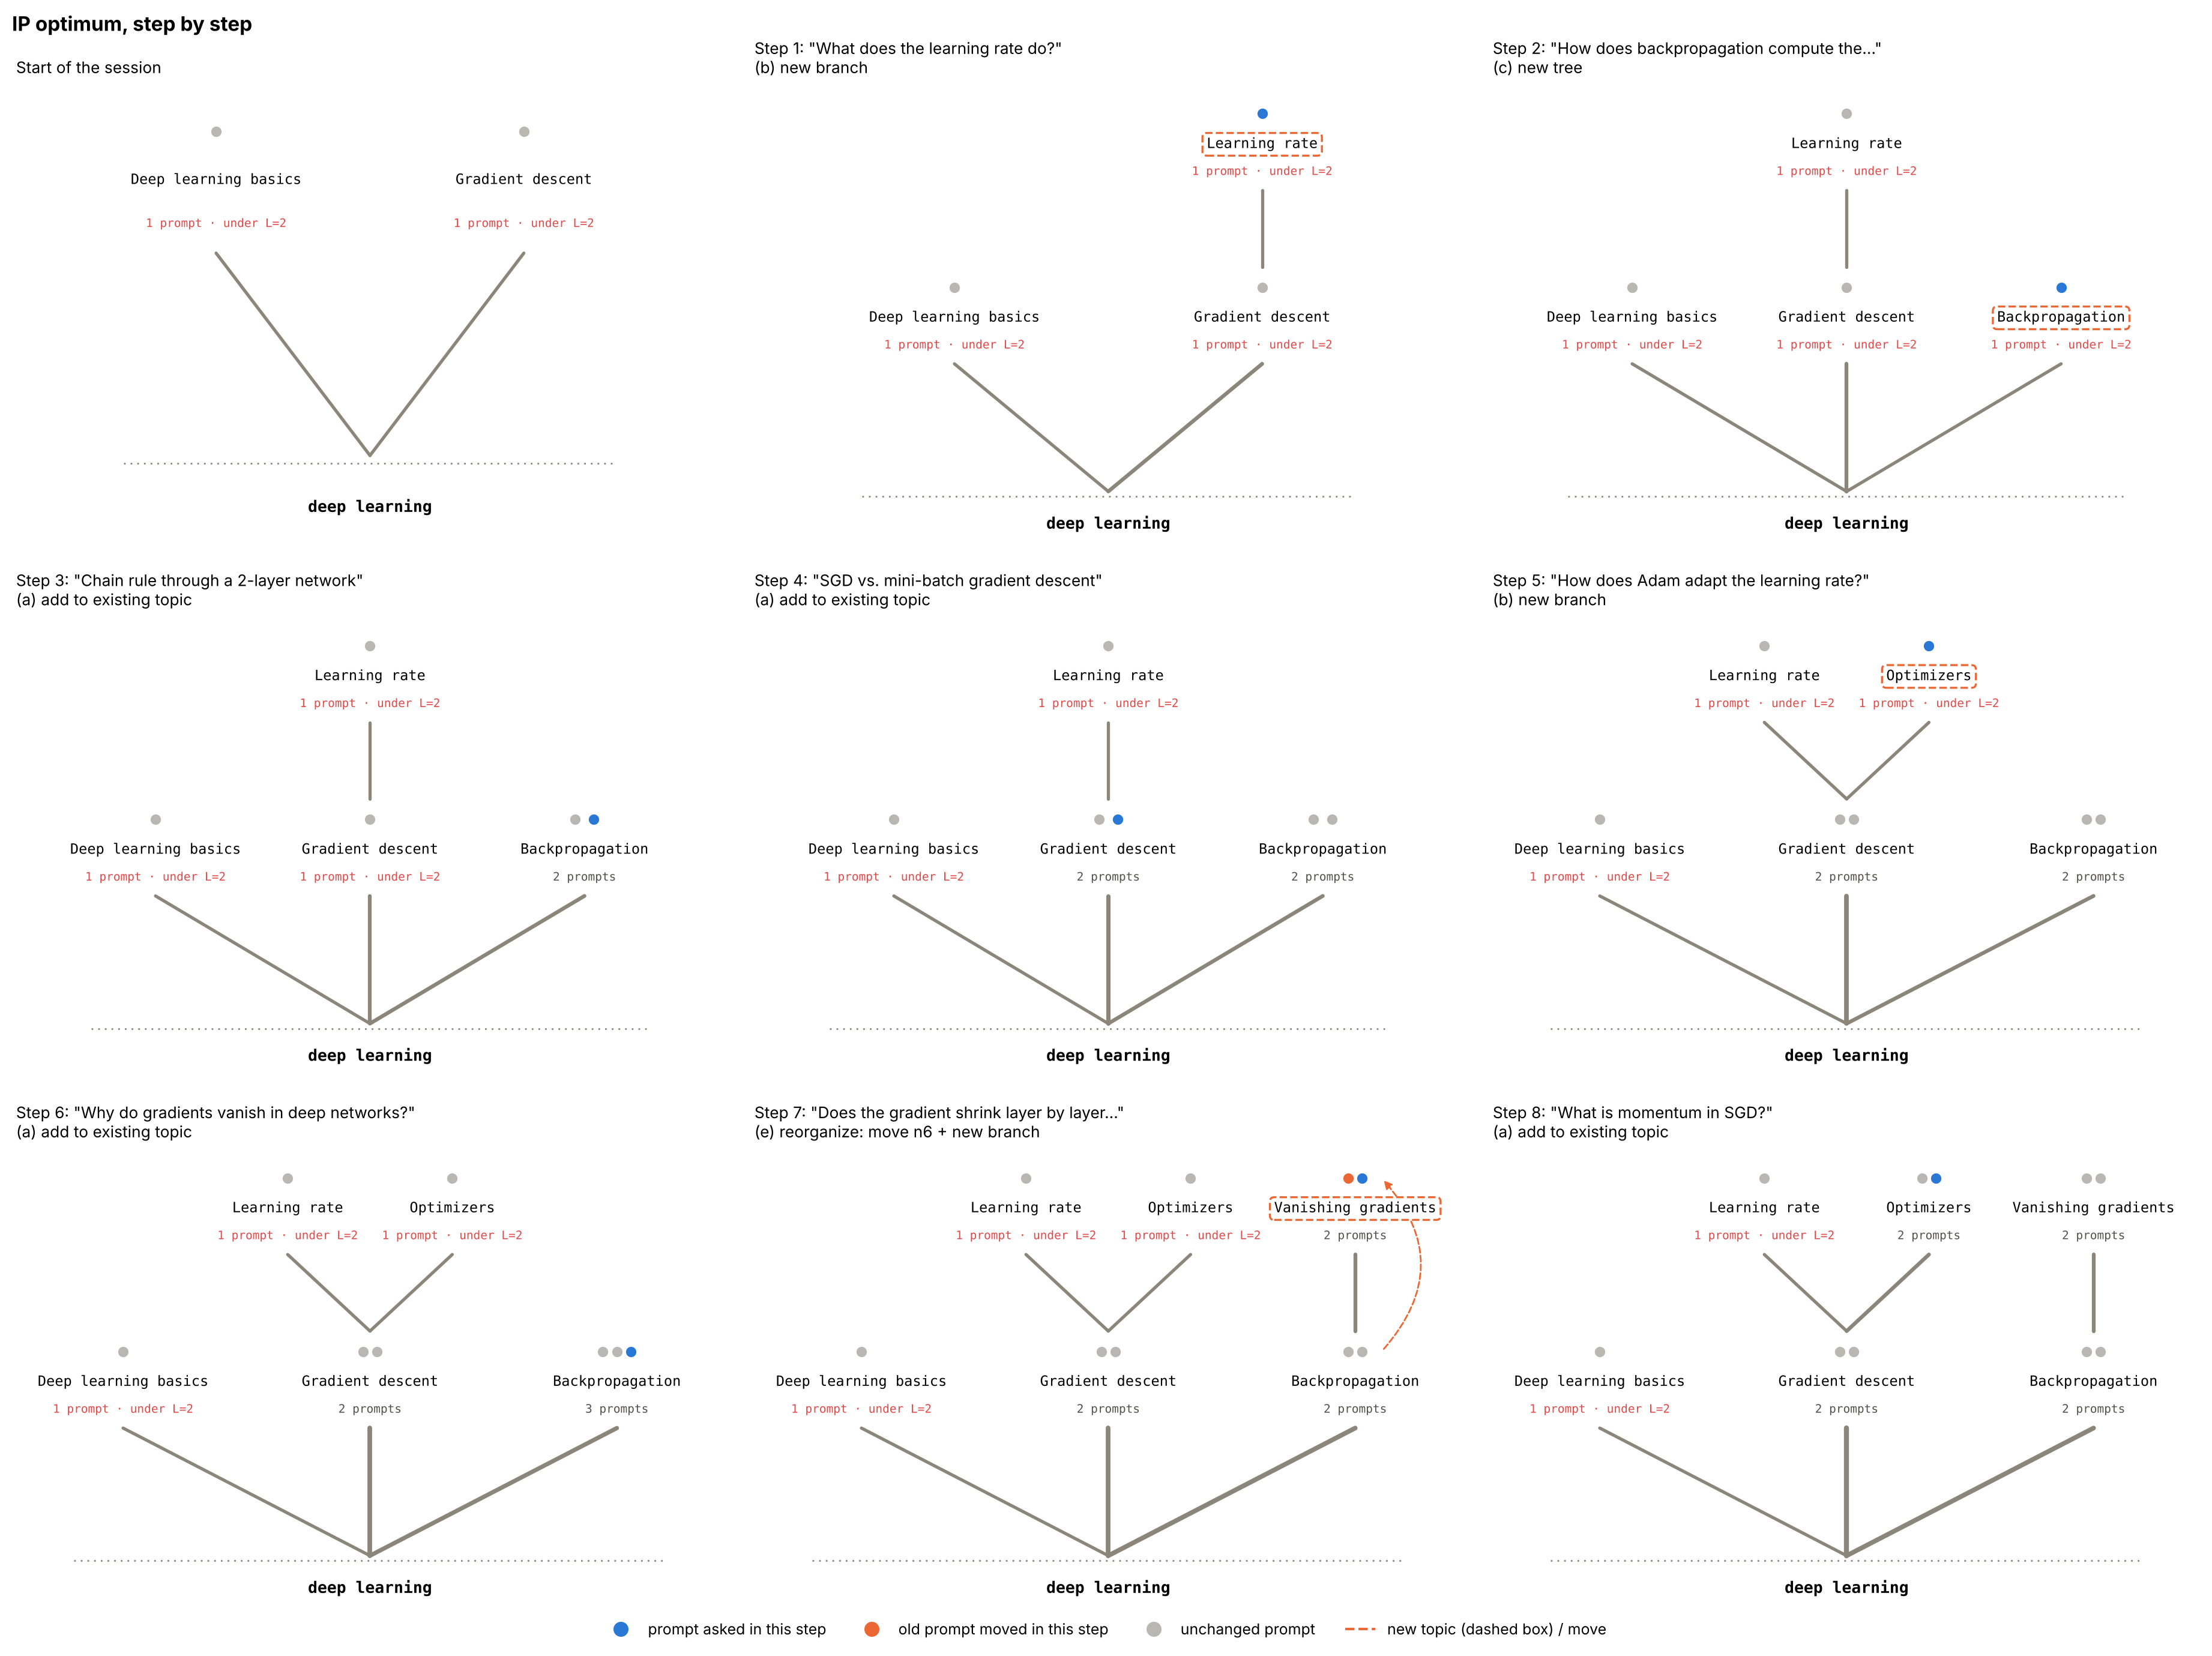

In [14]:
show_session(ip_history, "IP optimum, step by step")

## Visualization: one step in detail
Change `k` to look at any step.

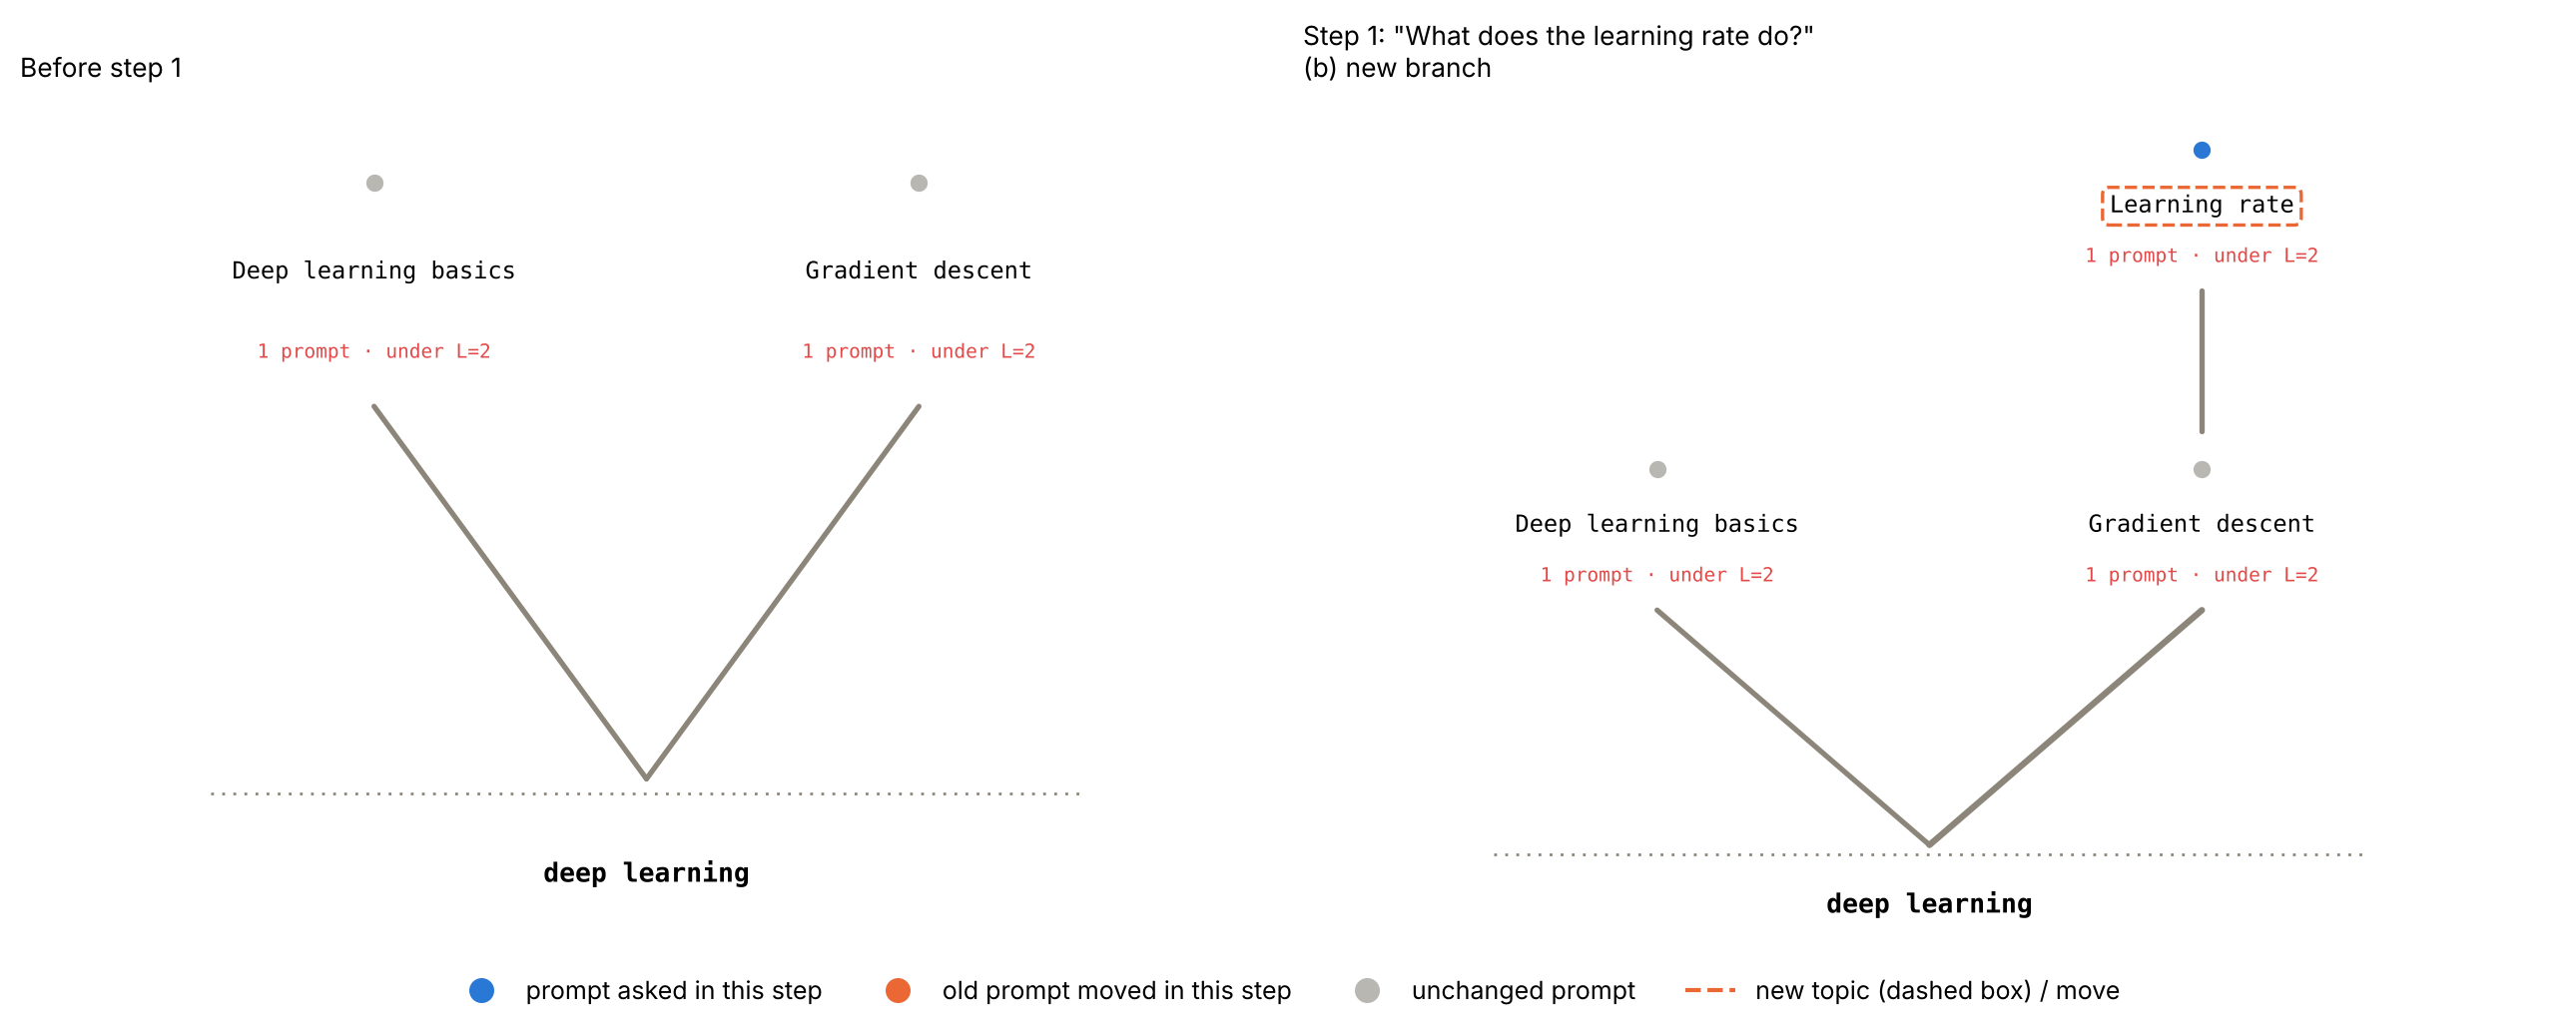

In [15]:
show_step(ip_history, k=1)

## Animation: watch a step happen
The same step as an animation: the tree before the step morphs into the tree after it. The new prompt drops in (blue), moved prompts glide to their new topic (orange), a newly created topic fades in. Use the player controls below the figure (play, pause, step frame by frame, loop).

`animate_step(history, k)` animates one step; `animate_session(history)` plays the whole session. With `gif="file.gif"` the animation is also saved as a GIF for slides or the report.

In [16]:
animate_step(ip_history, k=7)

In [ ]:
# the whole session (8 steps); add gif="session_ip.gif" to save it for slides
animate_session(ip_history)

## Why each decision? (computed from the current scores and weights)
For every step we list the open proposals and compare the IP's decision with the two simple alternatives: putting the new question into the **best existing topic**, or into the **best new topic without moving anything**. The number in brackets is how much **worse** that alternative is than the IP's decision, in units of fit (one judge level = 0.25); *(= IP decision)* marks the alternative the IP chose. *Margin* is the gap to the best alternative the IP did not choose: a small margin means a small change of a weight would flip the decision (see the what-if analysis). The table is recomputed from the current scores and weights.

In [18]:
def explain_session(history):
    rows = []
    for h in history:
        state, step, n = h["before"], h["step"], h["step"]["id"]
        keep = lambda c: {**state["assign"], n: c}                  # place n in c, nothing else moves
        opt = lambda c: evaluate_step(state, step, keep(c))["objective"]
        best_old = max(state["topics"], key=opt)
        cands = list(candidates_of(state, step))
        best_new = max(cands, key=opt) if cands else None
        ip = h["parts"]["objective"]
        def versus(c):                                # how much worse than the IP's decision
            if c is None:
                return "- (no proposal)"
            if keep(c) == h["after"]["assign"]:
                return f"{ALL_LABELS[c]}  (= IP decision)"
            return f"{ALL_LABELS[c]}  ({opt(c) - ip:+.2f})"
        others = [opt(c) for c in (best_old, best_new) if c is not None and keep(c) != h["after"]["assign"]]
        rows.append({
            "open proposals": ", ".join(ALL_LABELS[c] for c in cands) or "-",
            "IP decision": h["action"],
            "alternative: best existing topic": versus(best_old),
            "alternative: best new topic, no moves": versus(best_new),
            "margin": ip - max(others) if others else np.nan,
        })
    return pd.DataFrame(rows, index=pd.Index([h["k"] for h in history], name="step"))

print("Scores used:", SCORE_SOURCE)
explain_session(ip_history)

Scores used: step-by-step REPLAY of the batch answer in judge_scores.json for steps n1, n2, n3, n4, n5, n6, n7, n8 (not separate LLM calls)


,open proposals,IP decision,alternative: best existing topic,"alternative: best new topic, no moves",margin
step,,,,,
1,Learning rate,(b) new branch,Gradient descent (-0.06),Learning rate (= IP decision),0.06
2,Backpropagation,(c) new tree,Deep learning basics (-0.06),Backpropagation (= IP decision),0.06
3,-,(a) add to existing topic,Backpropagation (= IP decision),- (no proposal),NaN
4,SGD variants,(a) add to existing topic,Gradient descent (= IP decision),SGD variants (-0.19),0.19
5,"SGD variants, Optimizers",(b) new branch,Learning rate (-0.06),Optimizers (= IP decision),0.06
6,"SGD variants, Vanishing gradients",(a) add to existing topic,Backpropagation (= IP decision),Vanishing gradients (-0.07),0.07
7,"SGD variants, Vanishing gradients",(e) reorganize: move n6 + new branch,Deep learning basics (-0.18),Vanishing gradients (-0.12),0.12
8,SGD variants,(a) add to existing topic,Optimizers (= IP decision),SGD variants (-0.19),0.19


**How to read the table.** *(a)* with open proposals means the IP **rejected** them: placing the question in an existing topic is worth more than the cost of a new topic ($\lambda$, plus $\beta$ while it holds fewer than $L$ questions). A rejected proposal stays open; when a second related question arrives, creating it can become worth it, and an earlier question may then be moved into it (*(e)*). Small margins mark the decisions that depend most on the weights (Section 8) and on single LLM scores.

# 7. Human-made alternative designs
***
We run the same session with two best-effort rules a designer could write by hand. Both only place the new prompt and never move old prompts.

- **H1 – Always add to the best existing topic.** Never grows the tree; the status quo of a fixed folder structure.
- **H2 – Greedy best match.** Put the prompt in the best-scoring topic including the judge's proposals, i.e. open a new topic whenever the judge proposes a better one.

(The chronological chat list of today's chatbots is the baseline condition in Milestone 4; it has no topics, so it cannot be scored here.)

In [19]:
def h1_policy(state, step, params):
    best = max(state["topics"], key=lambda c: s(step["id"], c))
    return {**state["assign"], step["id"]: best}

def h2_policy(state, step, params):
    options = list(state["topics"]) + list(candidates_of(state, step))
    best = max(options, key=lambda c: s(step["id"], c))
    return {**state["assign"], step["id"]: best}

HISTORIES = {"H1: best existing topic": run_session(h1_policy),
             "H2: greedy best match": run_session(h2_policy),
             "IP optimum": ip_history}

# step-by-step: which action each design takes
pd.DataFrame({name: [code_of(h["action"]) for h in hist] for name, hist in HISTORIES.items()},
             index=pd.Index([f'{h["k"]}: {textwrap.shorten(h["step"]["text"], 45, placeholder="…")}'
                             for h in ip_history], name="step"))

,H1: best existing topic,H2: greedy best match,IP optimum
step,,,
1: What does the learning rate do?,a,b,b
2: How does backpropagation compute the…,a,c,c
3: Chain rule through a 2-layer network,a,a,a
4: SGD vs. mini-batch gradient descent,a,b,a
5: How does Adam adapt the learning rate?,a,b,b
6: Why do gradients vanish in deep networks?,a,b,a
7: Does the gradient shrink layer by layer with…,a,a,e
8: What is momentum in SGD?,a,a,a


To compare whole sessions we look at the **final tree** and the **path** to it:
- *mean fit*: average $s_{pc}$ of every prompt in its final topic (higher = prompts are where they belong);
- *topics over U* / *one-prompt topics*: imbalance of the final tree;
- *moves*: how many times an old prompt changed place during the session (disruption).

There is no single "winner" number here on purpose: summing the step objectives over a session would count the fit of old prompts again in every step, so it is not a fair comparison between different trees. The IP optimizes each step; the session metrics show what that leads to.

In [20]:
def session_metrics(history, params=PARAMS):
    final = history[-1]["after"]
    size = {c: sum(t == c for t in final["assign"].values()) for c in final["topics"]}
    moves = sum(sum(h["after"]["assign"][p] != h["before"]["assign"][p] for p in h["before"]["assign"]) for h in history)
    return {
        "mean fit": np.mean([s(p, c) for p, c in final["assign"].items()]),
        "topics": len(final["topics"]),
        "topics over U": sum(v > params["U"] for v in size.values()),
        "one-prompt topics": sum(v == 1 for v in size.values()),
        "moves": moves,
    }

pd.DataFrame({name: session_metrics(hist) for name, hist in HISTORIES.items()}).T

,mean fit,topics,topics over U,one-prompt topics,moves
H1: best existing topic,0.625,2.0,2.0,0.0,0.0
H2: greedy best match,1.000,7.0,0.0,4.0,0.0
IP optimum,0.950,6.0,0.0,2.0,1.0


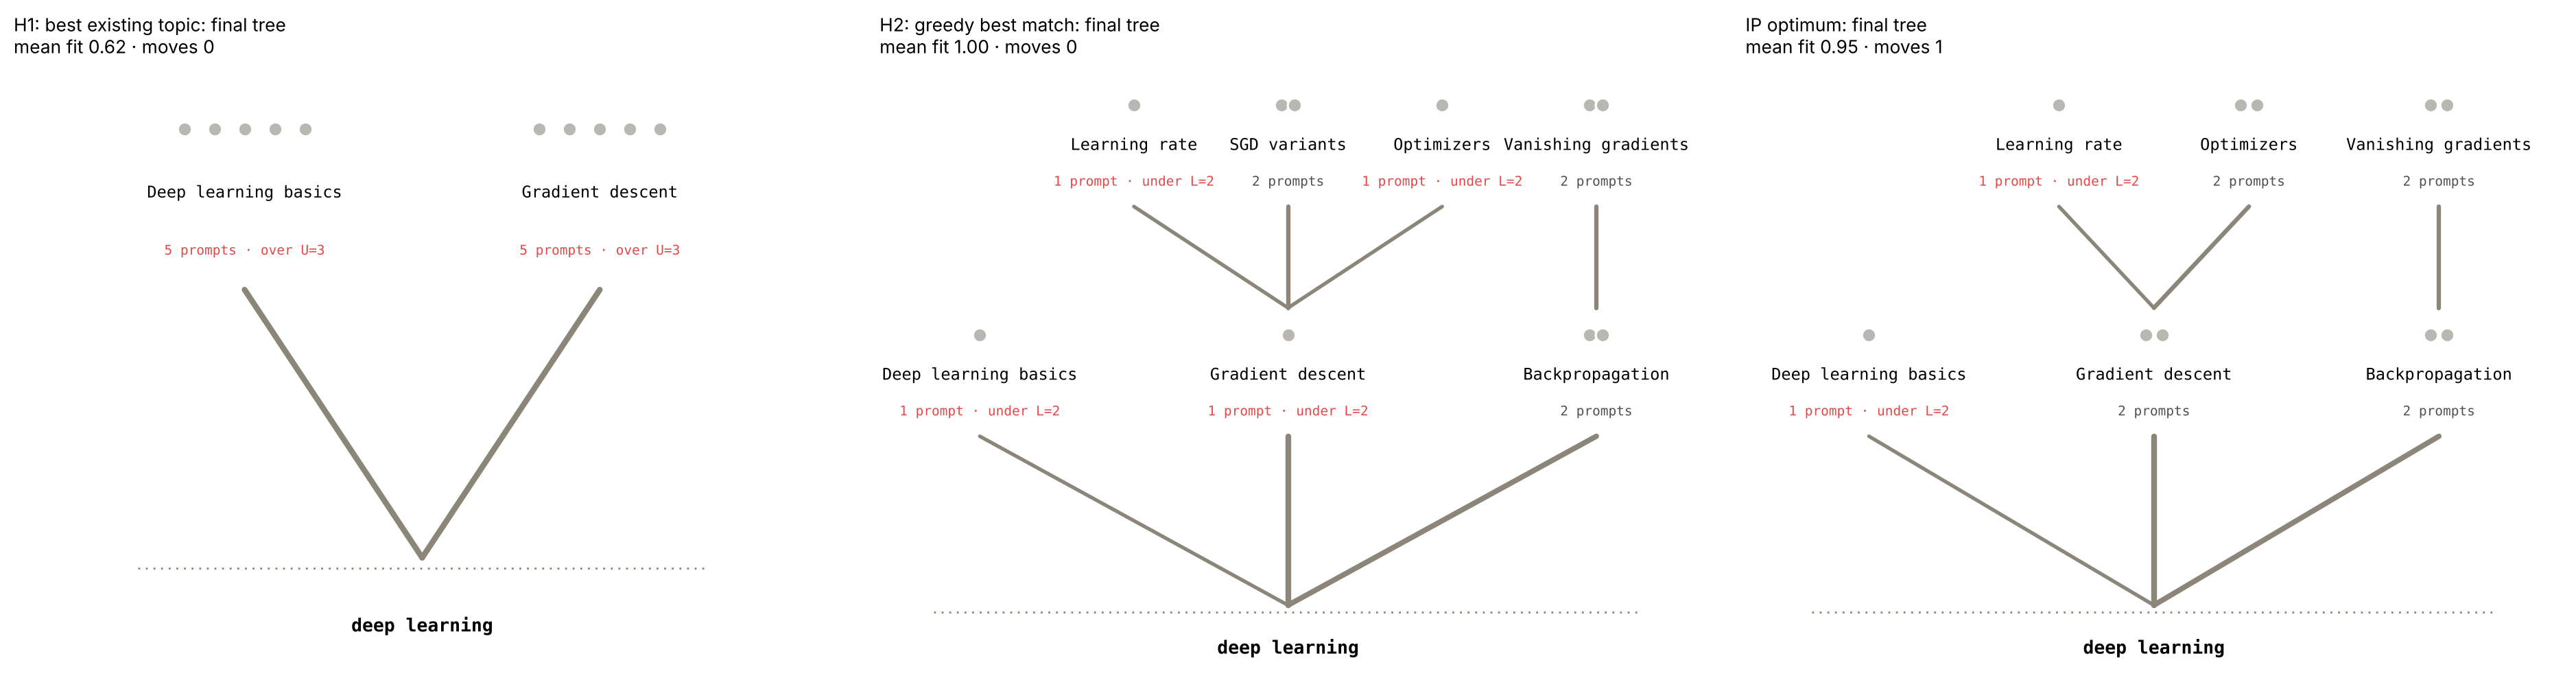

In [21]:
show_final_trees(HISTORIES, metrics=lambda h: f"mean fit {session_metrics(h)['mean fit']:.2f} · moves {session_metrics(h)['moves']}")

**Discussion (to be written for the report).** Compare the three final trees with the metrics above. H1 never creates topics, so questions pile up in few topics over $U$ with a low fit. H2 creates a topic for every proposal: the best fit, but more topics, several of them holding a single question. The IP creates a proposal only when it pays off, possibly later when a second related question arrives, and moves an old question only when the gain in fit and balance outweighs the disruption. Which balance is right for learners is what the what-if analysis below and the Milestone 4 study examine.

To look at the alternatives step by step, run `show_session(HISTORIES["H1: best existing topic"])` or `show_session(HISTORIES["H2: greedy best match"])`.

# 8. What-if analysis
***
We re-run the **whole session** for different weights. Each row shows the sequence of actions over the eight steps (a = add, b = new branch, c = new tree, e = reorganize), so one can see directly where the behaviour changes.

**How much do we value stability?** $F$ is the fixed cost of moving anything. $F = 0$ allows reorganizing freely; large $F$ freezes old prompts.

In [22]:
def sweep(name, values):
    rows = []
    for v in values:
        hist = run_session(params={**PARAMS, name: v})
        m = session_metrics(hist)
        rows.append({name: v, "actions (steps 1-8)": " ".join(code_of(h["action"]) for h in hist),
                     "topics": m["topics"], "moves": m["moves"], "mean fit": m["mean fit"],
                     "topics over U": m["topics over U"]})
    return pd.DataFrame(rows).set_index(name)

sweep("F", [0.0, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40])

,actions (steps 1-8),topics,moves,mean fit,topics over U
F,,,,,
0.00,b c a a b a e a,6,1,0.950,0
0.05,b c a a b a e a,6,1,0.950,0
0.10,b c a a b a e a,6,1,0.950,0
0.15,b c a a b a e a,6,1,0.950,0
0.20,b c a a b a e a,6,1,0.950,0
0.25,b c a a b a e a,6,1,0.950,0
0.30,b c a a b a b a,6,0,0.925,0
0.40,b c a a b a b a,6,0,0.925,0


**How expensive is a new topic?** $\lambda$ controls how readily the tree grows.

In [23]:
sweep("lam", [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.7])

,actions (steps 1-8),topics,moves,mean fit,topics over U
lam,,,,,
0.0,b c a b b b a a,7,0,1.000,0
0.1,b c a a b b a a,6,0,0.950,0
0.2,b c a a b a e a,6,1,0.950,0
0.3,a a e a b a e a,5,3,0.900,0
0.4,a a e a b a a a,4,1,0.825,0
0.5,a a e a b a a a,4,1,0.825,0
0.7,a a a a a e a e,4,3,0.825,0


**How large may a topic get?** $U$ decides when a topic counts as overloaded.

In [24]:
sweep("U", [2, 3, 4, 5, 6])

,actions (steps 1-8),topics,moves,mean fit,topics over U
U,,,,,
2,b c a a b b a a,6,0,0.95,0
3,b c a a b a e a,6,1,0.95,0
4,b c a a b a e a,6,1,0.95,0
5,b c a a b a e a,6,1,0.95,0
6,b c a a b a e a,6,1,0.95,0


# 9. Critical examination: limitations
***
**Inputs from the LLM**
- **One run, not validated.** Proposals and scores come from a single run of one model (Claude Sonnet 5.5) with a fixed prompt template. We did not repeat the run to measure how much the answers vary, and we did not compare the scores with human ratings. A different run or model could propose other topics or shift scores by one level, and that can change decisions with a small margin.
- **Inputs collected along one path.** The LLM is asked step by step along the IP's own path with the weights of Section 3, so it only ever sees the past. The human-made rules (Section 7) and the what-if runs (Section 8) reuse these proposals and scores; on their different paths the LLM might have proposed slightly different topics.
- **A score is fixed once asked.** Each score is asked once, when its question and topic both exist, and is not updated when later topics appear; this keeps earlier scores independent of later branches, but a score may become outdated as the tree grows.
- **Coarse scores.** The rubric has five levels, so fits differ in steps of 0.25. Many decisions are close (margins of 0.06–0.19 in Section 6), and with weights on the same grid two options can cost exactly the same; we chose $\beta = 0.12$ to avoid such ties.

**The model**
- **Myopic.** Each step is optimal on its own, but the solver does not know which questions will follow. A topic created early (e.g. *Learning rate*) may never get a second question, and a proposal rejected early is only created once a second question arrives.
- **Weights are assumptions.** $U$, $L$, $\lambda$, $\beta$, $\mu$, $F$ and $w_p = 1$ for all questions are set by us, not measured with users. The what-if analysis (Section 8) shows which decisions depend on them; how much learners actually value stability versus a precise grouping is open and is what the Milestone 4 study can inform.
- **Simplifications.** One subject only, at most one new topic per step, a proposal's parent is fixed by the LLM, old topics are never deleted or renamed, and the tree view shows at most two levels below the subject.

**The evaluation**
- **One short scripted session.** Eight questions on one subject, written by us. The results illustrate the behaviour of the model but do not show how it performs on real, longer and more diverse sessions.
- **Metrics are proxies.** Mean fit, topic sizes and number of moves describe the tree, not whether students find their questions faster or understand their progress better. That is tested in Milestone 4: the sequence of trees from this notebook is condition B, compared with rule H2 (or the chronological chat list) as condition A.

# Appendix: the LLM prompt (propose, then judge)
***
The step prompt that is sent for every new question (`judge_prompt.step_prompt`), shown for step 6 of the IP run: fixed parts plus the current tree, the open proposals, the missing scores and the new question. The prompts actually sent are stored in `llm_steps/<id>_prompt.txt`, next to the answers. The batch prompt below it (whole session at once, `judge_prompt.txt`) only produced the fallback file `judge_scores.json`.

In [25]:
h = ip_history[5]                                   # state before step 6
open_now = candidates_of(h["before"], h["step"])
print("=== step prompt (sent for every new question), before step 6 ===\n")
print(judge_prompt.step_prompt(SUBJECT, {**h["before"]["topics"], **open_now}, h["before"]["assign"],
                               all_prompts(), h["step"]["text"], open_ids=open_now))

print("\n\n=== batch prompt (fallback only: produced judge_scores.json) ===\n")
print(judge_prompt.batch_prompt(SUBJECT, INITIAL_TOPICS, all_prompts(), PLACED_0))

=== step prompt (sent for every new question), before step 6 ===

You help a study tool that sorts the questions a student asks an AI tutor into a knowledge tree about "deep learning".
A new question arrived. Do two tasks.

TASK 1 - PROPOSE
Decide whether the tree needs a new topic for the NEW question.
- Propose a new topic only if the question would get 5 for it and at most 4 for every topic that
  exists at that point. Otherwise propose nothing (null).
- At most one new topic per question. Name it in 1-3 words, as a student would label a folder.
- Choose the most specific fitting parent: an existing topic id, or ROOT to put it directly under
  "deep learning".
- Never propose a topic that already exists or was already proposed (same meaning, other words).
- Use the id NEW for your proposal.

TASK 2 - RATE with this rubric:

5 = the question is squarely about this topic; this is where a student would look for it.
4 = the question belongs to a more specific subtopic of this topic, and